# End to End Toy Project

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('/content/placement.csv')

In [3]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [4]:
df.shape

(100, 4)

In [5]:
df = df.iloc[:,1:]

In [6]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [7]:
import matplotlib.pyplot as plt

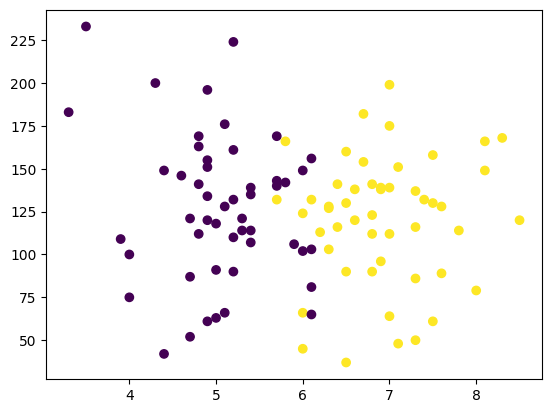

In [8]:
plt.scatter(df['cgpa'], df['iq'], c=df['placement'])

In [9]:
X = df.iloc[:, 0:2]
y = df.iloc[:, -1]

In [10]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [11]:
y

,placement
0,1
1,0
2,0
3,1
4,0
...,...
95,0
96,0
97,1
98,1


In [12]:
y.shape

(100,)

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1)

In [14]:
X_train

,cgpa,iq
9,5.1,66.0
53,8.3,168.0
43,6.8,141.0
85,5.8,166.0
37,8.1,149.0
...,...,...
99,6.2,113.0
78,6.1,81.0
47,5.2,161.0
3,7.4,132.0


In [15]:
y_train

,placement
9,0
53,1
43,1
85,1
37,1
...,...
99,1
78,0
47,0
3,1


In [16]:
X_test

,cgpa,iq
67,5.0,118.0
96,4.4,42.0
51,4.8,141.0
0,6.8,123.0
66,6.9,96.0
13,6.4,116.0
40,4.9,134.0
25,5.0,91.0
17,3.3,183.0
87,5.7,132.0


In [17]:
y_test

,placement
67,0
96,0
51,0
0,1
66,1
13,1
40,0
25,0
17,0
87,1


In [18]:
from sklearn.preprocessing import StandardScaler

In [19]:
scaler = StandardScaler()

In [20]:
X_train = scaler.fit_transform(X_train)

In [21]:
X_train

array([[-0.8620756 , -1.44938994],
       [ 1.99497587,  1.08883968],
       [ 0.65573299,  0.41695537],
       [-0.23709559,  1.03907047],
       [ 1.81641015,  0.6160322 ],
       [ 0.56645014,  1.43722413],
       [ 0.29860156,  0.41695537],
       [ 0.83429871, -0.30469815],
       [-0.05852987, -1.44938994],
       [-1.48705561,  0.6160322 ],
       [ 1.36999586, -0.87704405],
       [ 0.38788442, -0.85215944],
       [ 1.7271273 , -1.12589009],
       [-0.68350988, -0.08073672],
       [ 0.03075298, -0.52865959],
       [ 1.10214729, -0.95169786],
       [-1.12992418, -0.30469815],
       [ 0.92358157,  0.66580141],
       [-0.95135846, -1.52404375],
       [ 0.83429871,  1.2630319 ],
       [-0.68350988, -0.25492894],
       [-0.59422703,  0.26764774],
       [-0.8620756 ,  1.28791651],
       [ 0.83429871, -1.49915915],
       [ 1.10214729, -1.8475436 ],
       [-0.77279274,  0.19299393],
       [-1.84418704, -0.6033134 ],
       [-0.59422703, -0.42912117],
       [-0.8620756 ,

In [22]:
X_test = scaler.transform(X_test)

In [23]:
X_test

array([[-0.95135846, -0.15539053],
       [-1.48705561, -2.04662044],
       [-1.12992418,  0.41695537],
       [ 0.65573299, -0.03096751],
       [ 0.74501585, -0.70285182],
       [ 0.29860156, -0.20515974],
       [-1.04064132,  0.24276314],
       [-0.95135846, -0.82727484],
       [-2.46916705,  1.46210874],
       [-0.32637845,  0.19299393]])

In [24]:
from sklearn.linear_model import LogisticRegression

In [25]:
clf = LogisticRegression()

In [26]:
clf.fit(X_train, y_train)

LogisticRegression()

In [27]:
y_pred = clf.predict(X_test)

In [28]:
y_test

,placement
67,0
96,0
51,0
0,1
66,1
13,1
40,0
25,0
17,0
87,1


In [29]:
from sklearn.metrics import accuracy_score

In [30]:
accuracy_score(y_test, y_pred)

0.9

In [31]:
from mlxtend.plotting import plot_decision_regions

<Axes: >

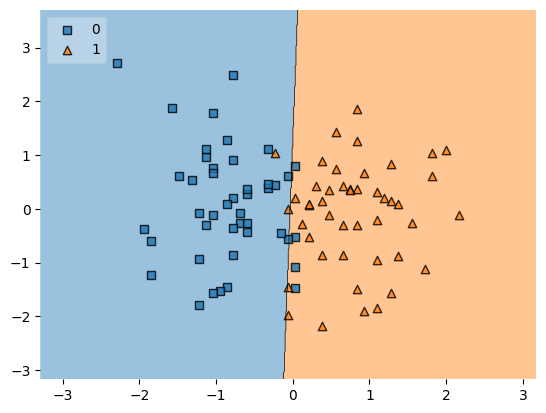

In [32]:
plot_decision_regions(X_train, y_train.values, clf=clf, legend=2)

In [33]:
import pickle

In [34]:
pickle.dump(clf, open('model.pkl', 'wb'))